<a href="https://colab.research.google.com/github/leahcimleirbag/TSA-hajime-capstone/blob/main/group_25_michael_ime_gabriel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Submission Summary

|  |  |
|---|---|
| Group number | 25 |
| Your full name | Michael Ime GABRIEL |
| Dataset | Bank Marketing (Term Deposit) |
| Depth track | Classification Depth |
| Team members | Michael Ime GABRIEL, Morah Paschaline, Chukwu Gabriel Tansi, Kashimawo Samuel Oluwasegun, Lawanson Itunu Moses, Uzu Onyenachie Fidelia, Oluwadoromi Emmanuel, Abdulrahman Ahmed Ozigi, Mere Doris Udochukwu |
| Final model | Gradient Boosting (200 trees, max_depth 3), threshold 0.24 |
| Stratified dummy F1 / ROC AUC | 0.49 / 0.51 |
| Final model F1 / ROC AUC | 0.69 / 0.79 |
| Leakage columns dropped | `duration`, but was dropped in Part 1 |
| Full run time on Colab | 3 minutes, approximately |

# Bank Marketing: From Raw Data to Real Predictions

**Business question.** A bank phones customers to sell a term deposit. Each call costs agent time, so the bank wants:

(1) A map of the natural customer groups

(2) A model that ranks customers by how likely they are to subscribe (`deposit = yes`), so agents call the right people first.

# Part 1. Data Foundation

In [ ]:
!pip -q install kagglehub imbalanced-learn

In [ ]:
import os, glob, sqlite3, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

T0 = time.time()
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')

import kagglehub
path = kagglehub.dataset_download('janiobachmann/bank-marketing-dataset')
csvs = glob.glob(os.path.join(path, '**', '*.csv'), recursive=True)
csv_path = next((c for c in csvs if os.path.basename(c) == 'bank.csv'), csvs[0])
print('Loaded:', csv_path)
raw = pd.read_csv(csv_path)
raw.head()

Using Colab cache for faster access to the 'bank-marketing-dataset' dataset.
Loaded: /kaggle/input/bank-marketing-dataset/bank.csv


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


### 1.1 Load into SQLite
We push the raw file into a SQLite database so the first questions are asked with SQL, as an analyst would on a company warehouse. The table is stored untouched; all cleaning happens later in pandas so the raw data stays reproducible.

In [ ]:
DB = 'bank_marketing.db'
conn = sqlite3.connect(DB)
raw.to_sql('bank', conn, if_exists='replace', index=False)
print(pd.read_sql('SELECT COUNT(*) AS n_rows FROM bank', conn))

   n_rows
0   11162


### 1.2 SQL queries
**Query 1: subscription rate by job.** Which occupations convert best? We keep only jobs with at least 50 customers so tiny groups do not produce misleading rates.

In [ ]:
q1 = '''
SELECT job,
       COUNT(*) AS n,
       ROUND(100.0 * AVG(deposit = 'yes'), 1) AS deposit_rate_pct,
       ROUND(AVG(balance), 0) AS avg_balance
FROM bank
GROUP BY job
HAVING n >= 50
ORDER BY deposit_rate_pct DESC
'''
pd.read_sql(q1, conn)

,job,n,deposit_rate_pct,avg_balance
0,student,360,74.7,1501.0
1,retired,778,66.3,2417.0
2,unemployed,357,56.6,1315.0
3,management,2566,50.7,1794.0
4,unknown,70,48.6,1945.0
5,admin.,1334,47.3,1196.0
6,self-employed,405,46.2,1865.0
7,technician,1823,46.1,1556.0
8,services,923,40.0,1081.0
9,housemaid,274,39.8,1366.0


**What we learned (Query 1).** Conversion varies enormously by occupation: students (about 75%) and retirees (about 66%) subscribe most, while blue-collar (about 36%), entrepreneurs (about 38%) and housemaids (about 40%) subscribe least. A spread of nearly 40 percentage points means `job` carries real signal and must stay in the model.

**Query 2: subscription rate by outcome of the previous campaign (`poutcome`).** Does having been contacted before, and how that went, change the odds?

In [ ]:
q2 = '''
SELECT poutcome,
       COUNT(*) AS n,
       ROUND(100.0 * AVG(deposit = 'yes'), 1) AS deposit_rate_pct,
       ROUND(AVG(previous), 2) AS avg_previous_contacts
FROM bank
GROUP BY poutcome
ORDER BY deposit_rate_pct DESC
'''
pd.read_sql(q2, conn)

,poutcome,n,deposit_rate_pct,avg_previous_contacts
0,success,1071,91.3,3.12
1,other,537,57.2,4.16
2,failure,1228,50.3,3.02
3,unknown,8326,40.7,0.00


**What we learned (Query 2).** A previous *success* is an extremely strong signal: about 91% of those customers subscribed again, against about 41% for customers never contacted before (`unknown`, three quarters of the data) and about 50% after a previous failure. This is why `unknown` must stay as a category instead of being treated as missing, and why `pdays = -1` becomes an explicit `contacted_before` flag later.

**Query 3: subscription rate and call effort by month.** Is there seasonality, and do we call harder when conversion is low?

In [ ]:
q3 = '''
SELECT month,
       COUNT(*) AS n,
       ROUND(100.0 * AVG(deposit = 'yes'), 1) AS deposit_rate_pct,
       ROUND(AVG(campaign), 2) AS avg_calls_this_campaign
FROM bank
GROUP BY month
ORDER BY deposit_rate_pct DESC
'''
pd.read_sql(q3, conn)

,month,n,deposit_rate_pct,avg_calls_this_campaign
0,dec,110,90.9,2.18
1,mar,276,89.9,2.00
2,sep,319,84.3,1.73
3,oct,392,82.4,1.51
4,apr,923,62.5,1.83
5,feb,776,56.8,2.16
6,aug,1519,45.3,3.51
7,jun,1222,44.7,2.85
8,nov,943,42.7,1.82
9,jul,1514,41.4,3.29


**What we learned (Query 3).** Volume and conversion are misaligned. May is by far the busiest month (2,824 customers) yet converts worst (about 33%), while December, March, September and October convert at 82-91% on only 110-392 customers each. Summer months also get the most calls per customer (about 3.3-3.5 in July/August) with below-average results. So `month` is informative and call effort is not being allocated by expected return. We encode it as an ordered number in Part 2.

### 1.3 Exploratory data analysis (EDA)

In [ ]:
print('Shape:', raw.shape)
print()
print(raw.dtypes)
print()
print('Missing values per column:')
print(raw.isna().sum())
print()
print('Duplicate rows:', raw.duplicated().sum())
print()
raw.describe().T

Shape: (11162, 17)

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
deposit      object
dtype: object

Missing values per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

Duplicate rows: 0



,count,mean,std,min,25%,50%,75%,max
age,11162.0,41.231948,11.913369,18.0,32.0,39.0,49.00,95.0
balance,11162.0,1528.538524,3225.413326,-6847.0,122.0,550.0,1708.00,81204.0
day,11162.0,15.658036,8.420740,1.0,8.0,15.0,22.00,31.0
duration,11162.0,371.993818,347.128386,2.0,138.0,255.0,496.00,3881.0
campaign,11162.0,2.508421,2.722077,1.0,1.0,2.0,3.00,63.0
pdays,11162.0,51.330407,108.758282,-1.0,-1.0,-1.0,20.75,854.0
previous,11162.0,0.832557,2.292007,0.0,0.0,0.0,1.00,58.0


Hidden missing values (the string "unknown") per categorical column:
  job: 70 (0.6%)
  education: 497 (4.5%)
  contact: 2346 (21.0%)
  poutcome: 8326 (74.6%)



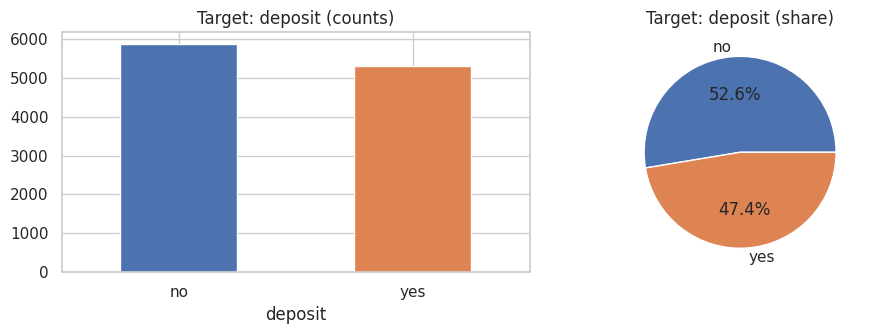


Positive-class rate: 0.474


In [ ]:
print('Hidden missing values (the string "unknown") per categorical column:')
for c in raw.select_dtypes('object').columns:
    n = (raw[c] == 'unknown').sum()
    if n:
        print(f'  {c}: {n} ({n/len(raw):.1%})')

print()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
raw['deposit'].value_counts().plot.bar(ax=ax[0], color=['#4C72B0', '#DD8452'])
ax[0].set_title('Target: deposit (counts)')
ax[0].tick_params(axis='x', rotation=0)
raw['deposit'].value_counts(normalize=True).plot.pie(ax=ax[1], autopct='%1.1f%%', colors=['#4C72B0', '#DD8452'])
ax[1].set_ylabel('')
ax[1].set_title('Target: deposit (share)')
plt.tight_layout()
plt.show()
print()
print('Positive-class rate:', round((raw['deposit'] == 'yes').mean(), 3))

**Target distribution.** The share of `yes` is close to half, so this dataset is **roughly balanced** (inside the 40-60% band). In Part 5 we still apply the imbalance techniques, but we expect them to change very little and we will show that with numbers.

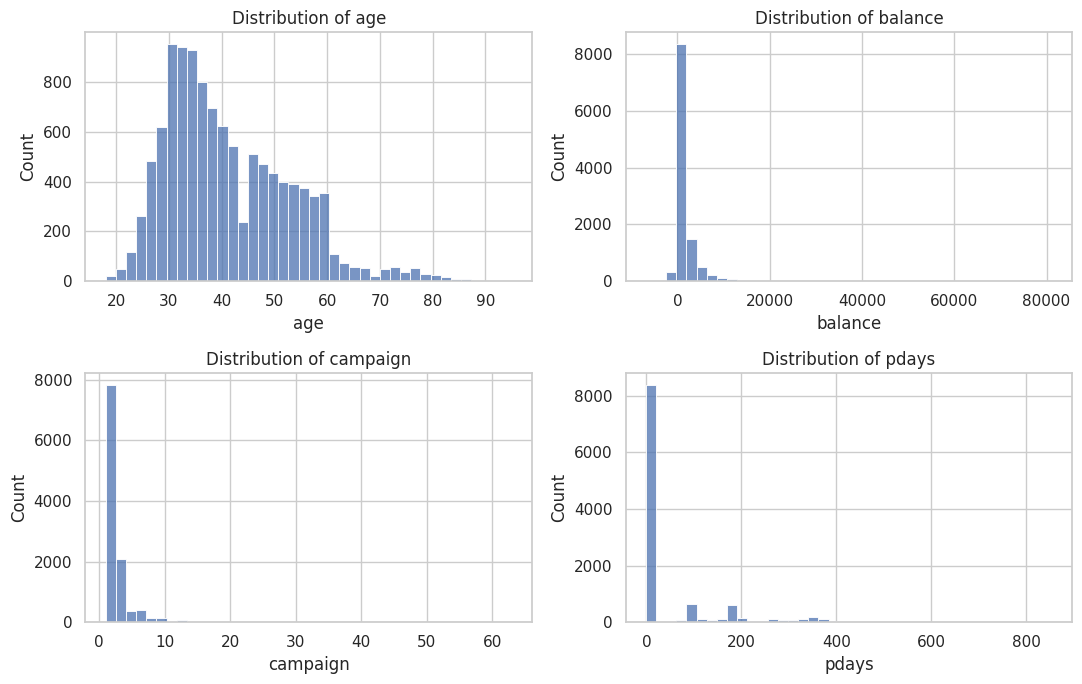

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ['age', 'balance', 'campaign', 'pdays']):
    sns.histplot(raw[col], bins=40, ax=ax, color='#4C72B0')
    ax.set_title(f'Distribution of {col}')
plt.tight_layout(); plt.show()

**Reading the distributions.** `age` is fairly bell-shaped (most customers 30-50). `balance`, `campaign` and `pdays` are strongly right-skewed with long tails, and `pdays` has a spike at -1 meaning "never contacted before". Those long tails and the -1 code drive the cleaning decisions below.

### 1.4 Cleaning (each step justified)

**Step 1: remove exact duplicate rows.** A duplicated customer record would sit in both train and test and inflate scores. If none exist this removes nothing.

In [ ]:
df = raw.copy()
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print('Rows dropped as duplicates:', n_before - len(df))

Rows dropped as duplicates: 0


**Step 2: turn the target into 0/1.** Models and metrics need a numeric positive class; `yes` = 1 = "subscribed", so recall means "share of real subscribers we catch".

In [ ]:
df['target'] = (df['deposit'] == 'yes').astype(int)
df = df.drop(columns='deposit')
df['target'].value_counts()

,count
target,
0,5873
1,5289


**Step 3: drop `duration` (leakage by timing).** `duration` is the length of the call that *produced* the outcome. It is only known after the call, so it cannot be used to decide whom to call. Long calls are mostly a consequence of interested customers. Keeping it would give a flattering but undeployable AUC (well above 0.9). We drop it and record it as a leakage column in the Submission Summary.

In [ ]:
df = df.drop(columns='duration')

**Step 4: keep `unknown` as its own category; do not impute.** Missingness here is informative (for `poutcome`, `unknown` literally means no previous campaign). Filling with the mode would invent information, and dropping those rows would delete most of the data (`poutcome`) or a large biased slice (`contact`). There are no true NaNs, so no `fillna` is needed.

**Step 5: handle `pdays = -1`.** `-1` is a code for "never contacted", not a real number of days; leaving it may confuse the algorithm. We store the meaning in a flag `contacted_before` and set `pdays` to 0 for them, so the flag carries "was contacted" and `pdays` carries "how long ago" for the rest.

In [ ]:
df['contacted_before'] = (df['pdays'] != -1).astype(int)
df.loc[df['pdays'] == -1, 'pdays'] = 0
print(df['contacted_before'].mean().round(3), 'of customers were contacted in a previous campaign')

0.254 of customers were contacted in a previous campaign


**Step 6: cap extreme outliers at the 1st/99th percentile (winsorise) instead of deleting rows.** `balance` has both very negative and very large values; `campaign`, `previous`, `pdays` have long upper tails. K-Means (distance-based) and linear models are pulled hard by a handful of extremes. Capping keeps every customer but limits their leverage; deleting rows would remove real customers and shrink the data. Tree models are unaffected either way.

In [ ]:
caps = {}
lo, hi = df['balance'].quantile([0.01, 0.99])
caps['balance'] = (lo, hi)
df['balance'] = df['balance'].clip(lo, hi)
for c in ['campaign', 'previous', 'pdays']:
    hi = df[c].quantile(0.99)
    caps[c] = (None, hi)
    df[c] = df[c].clip(upper=hi)
print({k: tuple(None if x is None else round(x, 1) for x in v) for k, v in caps.items()})
df_clean = df.copy()
df_clean.shape

{'balance': (-522.0, 13227.0), 'campaign': (None, np.float64(13.0)), 'previous': (None, np.float64(10.0)), 'pdays': (None, np.float64(425.4))}


(11162, 17)

# Part 2. Feature Engineering and Encoding

### 2.1 New features

**Feature 1: `age_band` (binning a continuous column).** Marketing works with life stages, not exact ages, and the age-conversion relationship is not linear (young adults and retirees respond differently from the middle). Five ordered bands (<30, 30-39, 40-49, 50-59, 60+) let even a linear model capture that shape.

**Feature 2: `total_contacts` = `campaign` + `previous` (count per row).** Customer fatigue depends on the *total* number of times the bank has bothered someone, across this and earlier campaigns, not on either number alone.

**Feature 3: `n_debts` = defaults + housing loan + personal loan (count per row).** A customer already carrying several obligations has less cash to lock into a deposit. One count summarises financial pressure better than three sparse yes/no flags.

**Feature 4: `balance_per_age` = `balance` / `age` (ratio).** Raw balance favours older customers who simply had longer to save. Balance per year of age shows who is saving *fast* relative to their stage, a plausible proxy for deposit capacity.

In [ ]:
df_fe = df_clean.copy()
df_fe['age_band'] = pd.cut(df_fe['age'], bins=[0, 29, 39, 49, 59, 120], labels=[0, 1, 2, 3, 4]).astype(int)
df_fe['total_contacts'] = df_fe['campaign'] + df_fe['previous']
df_fe['n_debts'] = ((df_fe['default'] == 'yes').astype(int)
                    + (df_fe['housing'] == 'yes').astype(int)
                    + (df_fe['loan'] == 'yes').astype(int))
df_fe['balance_per_age'] = df_fe['balance'] / df_fe['age']
df_fe[['age', 'age_band', 'campaign', 'previous', 'total_contacts', 'n_debts', 'balance', 'balance_per_age']].head()

,age,age_band,campaign,previous,total_contacts,n_debts,balance,balance_per_age
0,59,3,1,0,1,1,2343.0,39.711864
1,56,3,1,0,1,0,45.0,0.803571
2,41,2,1,0,1,1,1270.0,30.975610
3,55,3,1,0,1,1,2476.0,45.018182
4,54,3,2,0,2,0,184.0,3.407407


### 2.2 Encoding

**Binary yes/no columns (`default`, `housing`, `loan`) -> label encoding (0/1).** Two categories need only one column; one-hot would add a redundant mirror column.

**`month` -> ordered label (1-12).** Months have a natural calendar order and we saw seasonality in Query 3, so a single ordered number is compact. A limitation we accept: December and January are far apart numerically but adjacent in reality; the data only covers part of the year so this matters little.

**Nominal columns (`job`, `marital`, `education`, `contact`, `poutcome`) -> one-hot with `drop_first=True`.** These have no true numeric order (we do not want a model to think "management" is twice "admin"), so one-hot is correct. `education` is treated as nominal because it contains an `unknown` level that has no place on the primary < secondary < tertiary scale. We use `drop_first=True` because the dropped level is implied by all others being 0; keeping it makes the columns perfectly collinear, which destabilises logistic regression coefficients and adds nothing for trees.

In [ ]:
df_enc = df_fe.copy()
for c in ['default', 'housing', 'loan']:
    df_enc[c] = (df_enc[c] == 'yes').astype(int)

month_order = {m: i for i, m in enumerate(['jan', 'feb', 'mar', 'apr', 'may', 'jun',
                                            'jul', 'aug', 'sep', 'oct', 'nov', 'dec'], start=1)}
df_enc['month'] = df_enc['month'].map(month_order)
assert df_enc['month'].notna().all()

nominal = ['job', 'marital', 'education', 'contact', 'poutcome']
df_enc = pd.get_dummies(df_enc, columns=nominal, drop_first=True, dtype=int)

y = df_enc['target']
X = df_enc.drop(columns='target')
print('Feature matrix:', X.shape, '| all numeric:', all(np.issubdtype(t, np.number) for t in X.dtypes))

Feature matrix: (11162, 36) | all numeric: True


### 2.3 Scaling

**Choice: `StandardScaler`.** K-Means, PCA, KNN and logistic regression are distance/gradient based, so features on very different scales (balance in thousands vs 0/1 flags) would dominate. We chose standardisation over `MinMaxScaler` because min-max squeezes everything by the range, so any remaining extreme value compresses the rest of the column; z-scores are less distorted by that and fit PCA (which assumes centred data) naturally. Outliers are already capped in Part 1.

**Leakage-safe usage.** For **clustering/PCA** (unsupervised, label never used) we scale the whole matrix once below. For **classification** the scaler is placed *inside* each model Pipeline in Part 4, so it is fitted on the training fold only and the test set never influences it.

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler_all = StandardScaler()
X_scaled = scaler_all.fit_transform(X)
print('Scaled shape:', X_scaled.shape, '| mean ~', X_scaled.mean().round(3), '| std ~', X_scaled.std().round(3))

Scaled shape: (11162, 36) | mean ~ -0.0 | std ~ 1.0


# Part 3. Clustering Analysis

We cluster on the scaled feature matrix **without the label**, so the clusters are an honest, unsupervised map of customer types. Silhouette is computed on a 5,000-row random sample to keep the run fast.

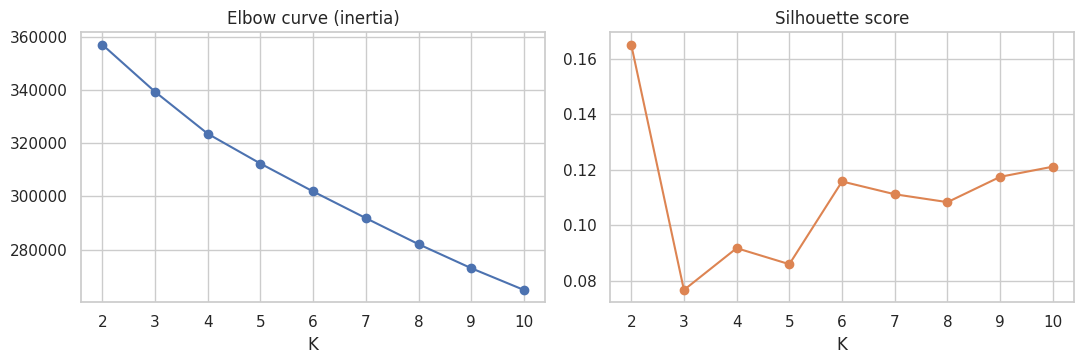

,0,1,2,3,4,5,6,7,8
K,2.0000,3.0000,4.0000,5.0000,6.0000,7.0000,8.0000,9.0000,10.0000
inertia,357019.0000,339307.0000,323534.0000,312318.0000,301823.0000,291815.0000,282017.0000,272990.0000,264812.0000
silhouette,0.1651,0.0767,0.0917,0.0859,0.1158,0.1112,0.1083,0.1175,0.1211


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Ks = list(range(2, 11))
inertias, sils = [], []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_scaled, km.labels_, sample_size=5000, random_state=RANDOM_STATE))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(Ks, inertias, 'o-')
ax[0].set_title('Elbow curve (inertia)')
ax[0].set_xlabel('K')
ax[1].plot(Ks, sils, 'o-', color='#DD8452')
ax[1].set_title('Silhouette score')
ax[1].set_xlabel('K')
plt.tight_layout()
plt.show()
pd.DataFrame({'K': Ks, 'inertia': np.round(inertias, 0), 'silhouette': np.round(sils, 4)}).T

### Choosing the final K
We combine two signals. The **elbow** is located objectively as the point farthest from the straight line joining the first and last points of the inertia curve. The **silhouette** tells us how well separated the clusters are at that K. We also reject K = 2 as a final answer unless it is clearly better: with many 0/1 columns a 2-cluster split usually just separates on one or two dummies and gives the business no useful segments.

In [ ]:
def elbow_k(ks, inert):
    x = np.array(ks, float); yv = np.array(inert, float)
    x = (x - x.min()) / (x.max() - x.min()); yv = (yv - yv.min()) / (yv.max() - yv.min())
    d = np.abs((yv[-1] - yv[0]) * x - (x[-1] - x[0]) * yv + x[-1] * yv[0] - yv[-1] * x[0]) \
        / np.hypot(yv[-1] - yv[0], x[-1] - x[0])
    return int(ks[int(np.argmax(d))])

K_ELBOW = elbow_k(Ks, inertias)
K_SIL = Ks[int(np.argmax(sils))]
K_SIL_3PLUS = Ks[1:][int(np.argmax(sils[1:]))]
print('Elbow K:', K_ELBOW, '| best silhouette K:', K_SIL, '| best silhouette K (K>=3):', K_SIL_3PLUS)

K_OVERRIDE = None
K_FINAL = K_OVERRIDE or max(K_ELBOW, 3)
print('Chosen K:', K_FINAL, '| silhouette at K:', round(sils[Ks.index(K_FINAL)], 4),
      '| max silhouette:', round(max(sils), 4))

Elbow K: 4 | best silhouette K: 2 | best silhouette K (K>=3): 10
Chosen K: 4 | silhouette at K: 0.0917 | max silhouette: 0.1651


**Justification.** The elbow method points to K = 4 (never below 3 by our rule). Silhouette is highest at K = 2 (about 0.17) but, as argued above, a 2-way split on mostly binary columns gives marketing little to act on; for K >= 3 the silhouette stays low and flat (about 0.08-0.12), with K = 4 near the bottom of that range (about 0.09). Both signals therefore say the same honest thing: the customer base has **no sharply separated clusters**, only overlapping tendencies. We still choose K = 4 because it is where extra clusters stop buying much variance reduction and it gives four segments small enough to describe and large enough (7% to 45% of customers) to matter. A larger K such as 9-10 has a slightly better silhouette (about 0.12) but fragments the customers into groups too small to profile reliably. We use silhouette to compare K values, not to claim crisp clusters. (If your team prefers another K, set `K_OVERRIDE` and rewrite this paragraph.)

In [ ]:
km_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
cluster = km_final.labels_

prof = df_fe.copy()
prof['cluster'] = cluster
prof_cols = ['age', 'balance', 'campaign', 'total_contacts', 'n_debts', 'contacted_before', 'previous']

summary = prof.groupby('cluster')[prof_cols].mean().round(2)
summary.insert(0, 'size', prof['cluster'].value_counts().sort_index())
summary['pct_of_customers'] = (100 * summary['size'] / len(prof)).round(1)
summary['top_job'] = prof.groupby('cluster')['job'].agg(lambda s: s.value_counts().index[0])
summary['pct_housing_loan'] = (100 * prof.assign(h=(prof['housing'] == 'yes')).groupby('cluster')['h'].mean()).round(1)
summary

,size,age,balance,campaign,total_contacts,n_debts,contacted_before,previous,pct_of_customers,top_job,pct_housing_loan
cluster,,,,,,,,,,,
0,2593,39.29,1588.31,1.92,4.98,0.59,1.0,3.07,23.2,management,48.6
1,798,65.65,2136.52,2.14,3.03,0.22,0.3,0.90,7.1,retired,14.8
2,2703,38.64,1702.32,2.61,2.62,0.49,0.0,0.00,24.2,management,37.9
3,5068,39.77,1094.22,2.65,2.65,0.76,0.0,0.00,45.4,blue-collar,56.8


### Cluster names
The helper below proposes a draft name from the three features on which each cluster differs most from the overall average (in standard deviations). **Replace the names in `cluster_names` with your own plain-English labels after reading the table above** (for example "young, debt-free, new-to-campaign customers").

In [ ]:
words = {'age': ('younger', 'older'), 'balance': ('low-balance', 'high-balance'),
         'campaign': ('lightly-called', 'heavily-called'), 'total_contacts': ('few-contact', 'many-contact'),
         'n_debts': ('debt-free', 'indebted'), 'contacted_before': ('new-to-campaign', 'previously-contacted'),
         'previous': ('no-history', 'repeat-history')}
z = (prof.groupby('cluster')[prof_cols].mean() - prof[prof_cols].mean()) / prof[prof_cols].std()
cluster_names = {}
for c, row in z.iterrows():
    top = row.abs().sort_values(ascending=False).index[:3]
    cluster_names[c] = ', '.join(words[f][int(row[f] > 0)] for f in top) + ' customers'
if len(set(cluster_names.values())) < len(cluster_names):   # safety: names must be unique
    cluster_names = {c: f'{n} (cluster {c})' for c, n in cluster_names.items()}
for c, n in cluster_names.items():
    print(f'Cluster {c}: {n}')

Cluster 0: previously-contacted, repeat-history, many-contact customers
Cluster 1: older, debt-free, high-balance customers
Cluster 2: new-to-campaign, no-history, few-contact customers
Cluster 3: new-to-campaign, no-history, indebted customers


### 2D visualisation with PCA
PCA compresses the scaled features to the two directions of greatest variance so the clusters can be drawn. The two axes will not show all the separation (see the explained variance in the title), so overlap in the picture does not mean the clusters are meaningless.

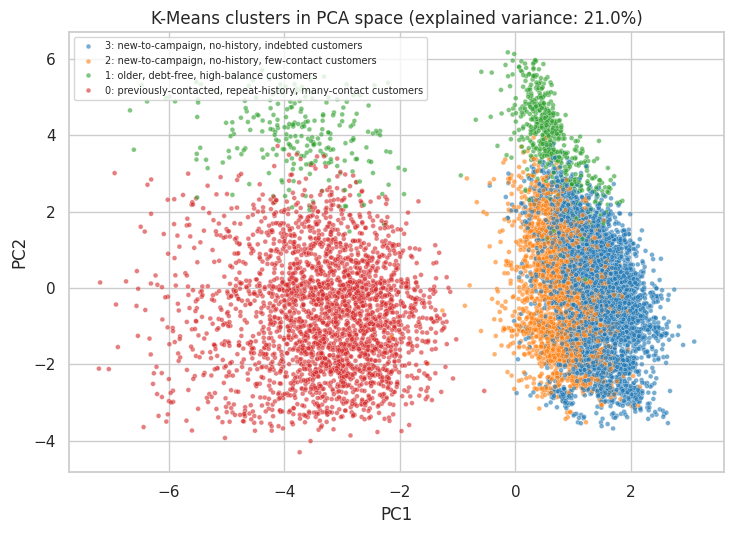

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pts = pca.fit_transform(X_scaled)
plt.figure(figsize=(7.5, 5.5))
sns.scatterplot(x=pts[:, 0], y=pts[:, 1], hue=[f'{c}: {cluster_names[c]}' for c in cluster], s=12, alpha=0.6, palette='tab10')
plt.title(f'K-Means clusters in PCA space (explained variance: {pca.explained_variance_ratio_.sum():.1%})')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(fontsize=7, loc='best')
plt.tight_layout()
plt.show()

# Part 4. Classification

**Setup.** We hold out 20% of the data as a test set with `stratify=y` so both sets keep the same share of subscribers. The dataset has more than 2,000 rows, so a single stratified split is used for the main comparison (the Depth Track adds stratified 5-fold CV on the training set). The test set is never used to choose a model setting or a threshold.

In [ ]:
# Split and Train
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, 'positive rate', round(y_train.mean(), 3))
print('Test :', X_test.shape, 'positive rate', round(y_test.mean(), 3))

Train: (8929, 36) positive rate 0.474
Test : (2233, 36) positive rate 0.474


**Model choices.**
- **Stratified dummy** (`DummyClassifier(strategy='stratified')`): the "random guessing" floor every real model must beat on positive-class F1 and AUC.
- **Logistic regression:** a transparent linear baseline; coefficients are easy to explain to the marketing team and it is fast.
- **K-Nearest Neighbours (k=25):** "customers similar to this one"; captures local patterns without assuming a form. A fairly large k smooths noise. Needs scaling, which the Pipeline provides.
- **Decision tree (depth 6, min 30 per leaf):** human-readable rules; the depth and leaf limits stop it memorising the training set.
- **Random forest:** averages many trees, handles non-linear effects and interactions, robust to outliers and little tuning needed.
- **Gradient boosting:** builds trees sequentially to correct earlier errors; usually the strongest tabular learner, at the price of being less interpretable.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

def make(model):
    return Pipeline([('scaler', StandardScaler()), ('clf', model)])

models = {
    'Stratified Dummy': make(DummyClassifier(strategy='stratified', random_state=RANDOM_STATE)),
    'Logistic Regression': make(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    'KNN (k=25)': make(KNeighborsClassifier(n_neighbors=25)),
    'Decision Tree': make(DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, random_state=RANDOM_STATE)),
    'Random Forest': make(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)),
    'Gradient Boosting': make(GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=RANDOM_STATE)),
}

def evaluate(y_true, proba, thr=0.5):
    pred = (np.asarray(proba) >= thr).astype(int)
    return {'Accuracy': accuracy_score(y_true, pred), 'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred),
            'ROC AUC': roc_auc_score(y_true, proba)}

proba_test, rows = {}, {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    proba_test[name] = pipe.predict_proba(X_test)[:, 1]
    rows[name] = evaluate(y_test, proba_test[name])

comparison = pd.DataFrame(rows).T.round(3)
comparison

,Accuracy,Precision,Recall,F1,ROC AUC
Stratified Dummy,0.510,0.483,0.490,0.486,0.509
Logistic Regression,0.678,0.693,0.577,0.630,0.732
KNN (k=25),0.678,0.700,0.562,0.624,0.724
Decision Tree,0.698,0.755,0.537,0.628,0.752
Random Forest,0.721,0.754,0.611,0.675,0.781
Gradient Boosting,0.740,0.784,0.622,0.694,0.791


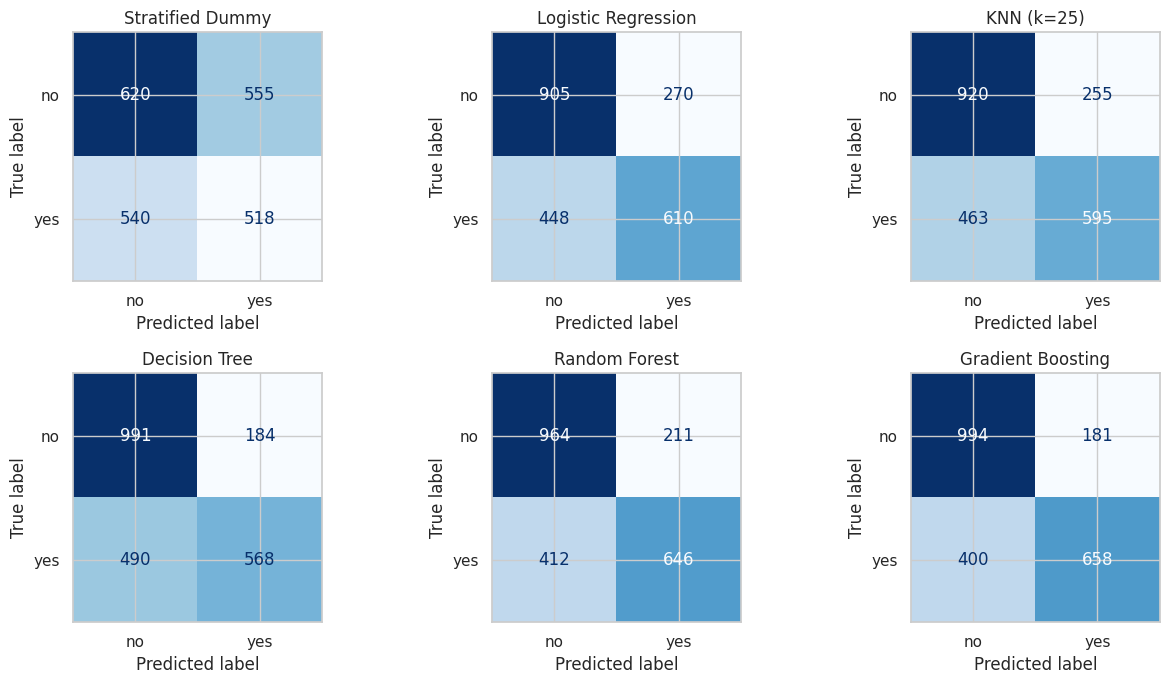

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (name, p) in zip(axes.ravel(), proba_test.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['no', 'yes']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [ ]:
dummy_f1, dummy_auc = comparison.loc['Stratified Dummy', 'F1'], comparison.loc['Stratified Dummy', 'ROC AUC']
real = comparison.drop(index='Stratified Dummy')
print('Dummy F1 / AUC:', dummy_f1, '/', dummy_auc)
print('Models beating the dummy on BOTH F1 and AUC:', list(real.index[(real['F1'] > dummy_f1) & (real['ROC AUC'] > dummy_auc)]))
print('Models with AUC >= 0.75:', list(real.index[real['ROC AUC'] >= 0.75]))
if (real['ROC AUC'] > 0.97).any():
    print('WARNING: near-perfect score, look for a leaking column!')

Dummy F1 / AUC: 0.486 / 0.509
Models beating the dummy on BOTH F1 and AUC: ['Logistic Regression', 'KNN (k=25)', 'Decision Tree', 'Random Forest', 'Gradient Boosting']
Models with AUC >= 0.75: ['Decision Tree', 'Random Forest', 'Gradient Boosting']


**Reading the table.** The stratified dummy scores F1 about 0.49 and ROC AUC about 0.51 (pure chance), and all five real models beat it on both metrics. The ordering is clear: gradient boosting (AUC about 0.79) > random forest (about 0.78) > decision tree (about 0.75) > logistic regression (about 0.73) > KNN (about 0.72). The tree ensembles lead because the signal is non-linear and interaction-heavy (previous outcome x month x contact channel). Logistic regression and KNN fall slightly under the 0.75 AUC bar on the test split, which is why we do not choose them as the final model. No score is anywhere near 1.0, consistent with having removed `duration`.

# Part 5. Imbalance Handling

**Expectation.** The positive rate is close to 50%, so the classes are already balanced. Class weights and SMOTE exist to stop a model from ignoring a rare class; here the model already sees both classes about equally, so we expect little change. Threshold tuning is different: it does not change the *ranking* (so ROC AUC stays identical) but moves the operating point along the precision/recall trade-off to match business cost. We apply **all three** techniques and test the expectation with numbers. All settings are chosen on the training set only.

**Business cost used for threshold tuning.** A call costs the bank 1 unit (agent time). A missed subscriber (false negative) costs 3 units in lost margin net of the call. So we accept calling roughly three non-buyers to catch one buyer. These two numbers are assumptions the bank should replace with real figures.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

COST_FP, COST_FN = 1.0, 3.0
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def rf(**kw):
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE, **kw)

def best_threshold(y_true, proba):
    y_true = np.asarray(y_true)
    grid = np.linspace(0.05, 0.95, 91)
    costs = []
    for t in grid:
        pred = proba >= t
        fp = ((pred == 1) & (y_true == 0)).sum(); fn = ((pred == 0) & (y_true == 1)).sum()
        costs.append(COST_FP * fp + COST_FN * fn)
    costs = np.array(costs)
    return float(grid[int(np.argmin(costs))]), grid, costs

def cost_per_1000(y_true, proba, thr):
    pred = proba >= thr; y_true = np.asarray(y_true)
    fp = ((pred == 1) & (y_true == 0)).sum(); fn = ((pred == 0) & (y_true == 1)).sum()
    return (COST_FP * fp + COST_FN * fn) / len(y_true) * 1000

# Technique A: class weights
pipe_cw = make(rf(class_weight='balanced_subsample')).fit(X_train, y_train)
p_cw = pipe_cw.predict_proba(X_test)[:, 1]

# Technique B: SMOTE (inside the pipeline so synthetic rows are made from training folds only)
pipe_sm = ImbPipeline([('scaler', StandardScaler()), ('smote', SMOTE(random_state=RANDOM_STATE)), ('clf', rf())]).fit(X_train, y_train)
p_sm = pipe_sm.predict_proba(X_test)[:, 1]

# Technique C: threshold tuning on out-of-fold training predictions of the baseline forest
oof_base = cross_val_predict(clone(models['Random Forest']), X_train, y_train, cv=skf, method='predict_proba')[:, 1]
thr_c, grid, costs_c = best_threshold(y_train, oof_base)

# Combined: class weights + threshold tuning (our candidate final model)
oof_cw = cross_val_predict(make(rf(class_weight='balanced_subsample')), X_train, y_train, cv=skf, method='predict_proba')[:, 1]
thr_d, _, costs_d = best_threshold(y_train, oof_cw)
print('Cost-optimal thresholds -> baseline forest:', round(thr_c, 2), '| class-weighted forest:', round(thr_d, 2))

Cost-optimal thresholds -> baseline forest: 0.24 | class-weighted forest: 0.25


### Precision-recall curve and the cost-based threshold
The curve below uses out-of-fold training predictions (never the test set). The marked point is the threshold that minimises `1 x FP + 3 x FN`. Because a missed buyer is three times as costly as a wasted call, the optimum sits **below** the default 0.5: we call more people, gaining recall and giving up some precision.

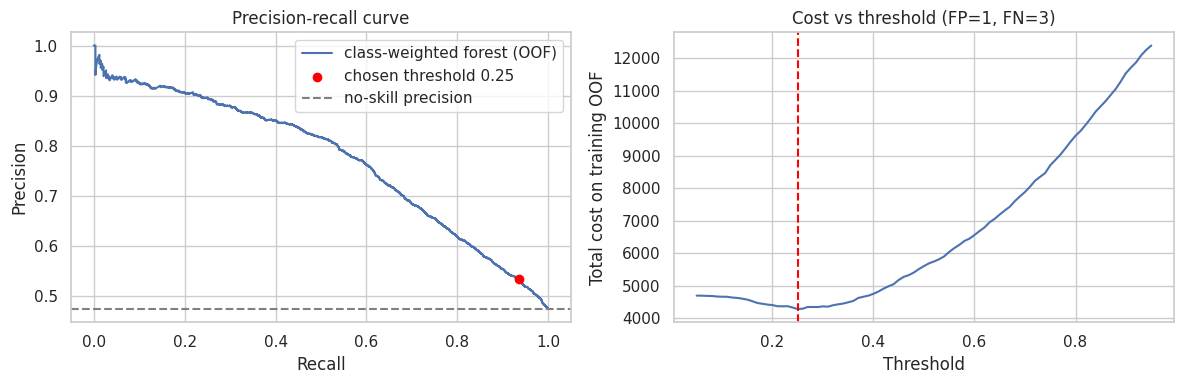

In [ ]:
prec, rec, thr_arr = precision_recall_curve(y_train, oof_cw)
pred_at = oof_cw >= thr_d
p_at = precision_score(y_train, pred_at); r_at = recall_score(y_train, pred_at)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rec, prec, label='class-weighted forest (OOF)')
ax[0].scatter([r_at], [p_at], color='red', zorder=5, label=f'chosen threshold {thr_d:.2f}')
ax[0].axhline(y_train.mean(), ls='--', color='grey', label='no-skill precision')
ax[0].set_xlabel('Recall'); ax[0].set_ylabel('Precision'); ax[0].set_title('Precision-recall curve'); ax[0].legend()
ax[1].plot(grid, costs_d); ax[1].axvline(thr_d, color='red', ls='--')
ax[1].set_xlabel('Threshold'); ax[1].set_ylabel('Total cost on training OOF'); ax[1].set_title('Cost vs threshold (FP=1, FN=3)')
plt.tight_layout(); plt.show()

In [ ]:
base_p = proba_test['Random Forest']
variants = {
    'Baseline forest (thr 0.50)':            (base_p, 0.5),
    'A: class weights (thr 0.50)':           (p_cw, 0.5),
    'B: SMOTE (thr 0.50)':                   (p_sm, 0.5),
    f'C: threshold tuning (thr {thr_c:.2f})': (base_p, thr_c),
    f'A+C: class weights + threshold (thr {thr_d:.2f})': (p_cw, thr_d),
}
tab = {}
for name, (p, t) in variants.items():
    m = evaluate(y_test, p, t)
    m['Threshold'] = t
    m['Cost per 1000 customers'] = cost_per_1000(y_test, p, t)
    tab[name] = m
imbalance_table = pd.DataFrame(tab).T
imbalance_table = imbalance_table[['Threshold', 'Precision', 'Recall', 'F1', 'ROC AUC', 'Cost per 1000 customers']].round(3)
imbalance_table['dF1 vs baseline'] = (imbalance_table['F1'] - imbalance_table.iloc[0]['F1']).round(3)
imbalance_table['dAUC vs baseline'] = (imbalance_table['ROC AUC'] - imbalance_table.iloc[0]['ROC AUC']).round(3)
print('Positive-class rate (train):', round(y_train.mean(), 3))
imbalance_table

Positive-class rate (train): 0.474


,Threshold,Precision,Recall,F1,ROC AUC,Cost per 1000 customers,dF1 vs baseline,dAUC vs baseline
Baseline forest (thr 0.50),0.50,0.754,0.611,0.675,0.781,648.007,0.000,0.000
A: class weights (thr 0.50),0.50,0.745,0.612,0.672,0.780,650.246,-0.003,-0.001
B: SMOTE (thr 0.50),0.50,0.743,0.626,0.679,0.778,634.572,0.004,-0.003
C: threshold tuning (thr 0.24),0.24,0.538,0.936,0.683,0.781,472.459,0.008,0.000
A+C: class weights + threshold (thr 0.25),0.25,0.533,0.929,0.677,0.780,486.789,0.002,-0.001


**Interpretation.** With 47% positives, class weights and SMOTE barely move the numbers: F1 changes by +0.009 (class weights) and +0.004 (SMOTE) and ROC AUC by -0.001 and -0.003 against the baseline forest, differences smaller than the fold-to-fold noise seen in the Depth Track. This is the expected result: the forest was already seeing both classes about equally, so reweighting or synthesising extra minority rows has almost nothing to correct. Threshold tuning leaves **AUC unchanged by construction** (same ranking of customers) but moves the operating point a lot: lowering the threshold from 0.50 to about 0.24 lifts recall from about 0.61 to about 0.94 and drops precision from about 0.75 to about 0.54, which cuts the expected cost from about 648 to about 472 per 1,000 customers (roughly 27% lower) under our 1:3 cost assumption. F1 hardly changes because F1 weighs precision and recall equally while our business cost does not. So for this dataset the lever that matters is the business-driven threshold, not rebalancing. SMOTE on one-hot columns also creates fractional dummy values, a further reason it is unattractive here.

# Part 6. The Tie-In

We now join the unsupervised clusters from Part 3 to the label we kept aside, to see whether the groups found *without* the label line up with who actually subscribes.

In [ ]:
tie = pd.DataFrame({'cluster': cluster, 'target': y.values})
rate = tie.groupby('cluster')['target'].agg(['size', 'mean']).rename(columns={'size': 'n', 'mean': 'positive_rate'})
rate['lift_vs_overall'] = rate['positive_rate'] / y.mean()
rate['name'] = [cluster_names[c] for c in rate.index]
print('Overall positive rate:', round(y.mean(), 3))
rate.round(3)

Overall positive rate: 0.474


,n,positive_rate,lift_vs_overall,name
cluster,,,,
0,2593,0.656,1.384,"previously-contacted, repeat-history, many-con..."
1,798,0.667,1.407,"older, debt-free, high-balance customers"
2,2703,0.461,0.974,"new-to-campaign, no-history, few-contact custo..."
3,5068,0.357,0.754,"new-to-campaign, no-history, indebted customers"


In [ ]:
from scipy.stats import chi2_contingency
from sklearn.model_selection import cross_val_score
chi2, pval, _, _ = chi2_contingency(pd.crosstab(tie['cluster'], tie['target']))
cl_only = pd.get_dummies(tie['cluster'], prefix='c', drop_first=True, dtype=int)
auc_cluster_only = cross_val_score(LogisticRegression(max_iter=1000), cl_only, y, cv=skf, scoring='roc_auc').mean()
auc_full = cross_val_score(models['Logistic Regression'], X, y, cv=skf, scoring='roc_auc').mean()
print(f'Chi-square test cluster vs label: chi2={chi2:.1f}, p={pval:.2e}')
print(f'ROC AUC predicting the label from cluster membership alone: {auc_cluster_only:.3f}')
print(f'ROC AUC of logistic regression on all features (5-fold CV): {auc_full:.3f}')

Chi-square test cluster vs label: chi2=741.2, p=2.48e-160
ROC AUC predicting the label from cluster membership alone: 0.636
ROC AUC of logistic regression on all features (5-fold CV): 0.741


**Were any clusters strong predictors?** Partly. The positive rate ranges from about 36% to about 67% across the four clusters (overall 47%), and the chi-square test is overwhelmingly significant, so the clusters, which never saw the label, do line up with who subscribes. Cluster 0 (previously contacted, repeat history; 23% of customers) and cluster 1 (older, debt-free, high-balance; 7%) subscribe at about 66-67% (lift about 1.4). Cluster 2 (new-to-campaign, few contacts) sits at about 46%, i.e. no better than average, and cluster 3 (new-to-campaign, indebted; the largest group at 45%) is the weakest at about 36%. This matches the SQL findings: previous campaign history, being older/retired and carrying fewer debts all go with subscribing. But the clusters are only a *moderate* predictor: a model using cluster membership alone reaches an AUC of about 0.64, versus about 0.74 for logistic regression on all features and about 0.79 for gradient boosting. What that tells us about the data: the signal is real but spread across many features (month, contact channel, balance, day) that cut *across* the customer-type groups, so segmenting customers by who they are is not enough to decide who to call. Clusters 2 and 3 in particular are large and look similar to each other, yet differ by about 10 points in subscription rate, and only a supervised model can separate customers inside them.

# Depth Track: Classification

We go deeper on classification in three ways: (1) five real classifiers evaluated with stratified 5-fold cross-validation on the training set (mean and standard deviation of every metric); (2) all ROC curves on one chart; (3) a comparison of feature importance across models. The test set stays untouched during cross-validation.

In [ ]:
from sklearn.model_selection import cross_validate
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'}
cv_rows = {}
for name, pipe in models.items():
    if name == 'Stratified Dummy':
        continue
    res = cross_validate(clone(pipe), X_train, y_train, cv=skf, scoring=scoring, n_jobs=-1)
    cv_rows[name] = {m: f"{res['test_' + m].mean():.3f} +/- {res['test_' + m].std():.3f}" for m in scoring}
cv_table = pd.DataFrame(cv_rows).T
cv_table

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.687 +/- 0.015,0.692 +/- 0.017,0.612 +/- 0.025,0.649 +/- 0.019,0.746 +/- 0.009
KNN (k=25),0.676 +/- 0.012,0.695 +/- 0.018,0.565 +/- 0.015,0.623 +/- 0.013,0.729 +/- 0.007
Decision Tree,0.683 +/- 0.006,0.709 +/- 0.026,0.567 +/- 0.053,0.628 +/- 0.025,0.739 +/- 0.003
Random Forest,0.719 +/- 0.007,0.743 +/- 0.013,0.624 +/- 0.021,0.678 +/- 0.011,0.776 +/- 0.006
Gradient Boosting,0.733 +/- 0.010,0.765 +/- 0.011,0.630 +/- 0.018,0.691 +/- 0.013,0.788 +/- 0.004


**What cross-validation tells us.** The fold-to-fold standard deviations are small (about 0.003-0.009 for AUC), so the model ranking is stable and not an accident of one split. Gradient boosting leads on cross-validated AUC (about 0.788 +/- 0.004) and F1 (about 0.691), ahead of the random forest (about 0.776 +/- 0.006 and 0.678). The gap is about two standard deviations, so we treat gradient boosting as modestly but genuinely better. Logistic regression (about 0.746) and the decision tree (about 0.739) are close to each other, and KNN is weakest (about 0.729).

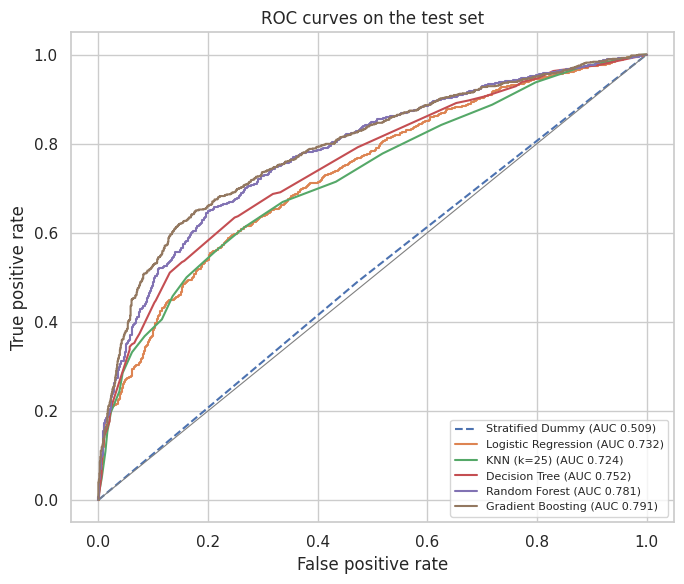

In [ ]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(7, 6))
for name, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})", ls='--' if 'Dummy' in name else '-')
plt.plot([0, 1], [0, 1], color='grey', lw=0.8)
plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.title('ROC curves on the test set')
plt.legend(loc='lower right', fontsize=8); plt.tight_layout(); plt.show()

                  Logistic Regression |coef|  Decision Tree  Random Forest  \
poutcome_success                       0.166          0.365          0.057   
contact_unknown                        0.105          0.198          0.057   
month                                  0.007          0.148          0.086   
n_debts                                0.038          0.123          0.045   
day                                    0.020          0.026          0.096   
balance_per_age                        0.004          0.037          0.106   
age                                    0.068          0.006          0.093   
pdays                                  0.003          0.070          0.046   
balance                                0.043          0.000          0.103   
age_band                               0.066          0.000          0.033   
campaign                               0.043          0.008          0.038   
marital_married                        0.026          0.018     

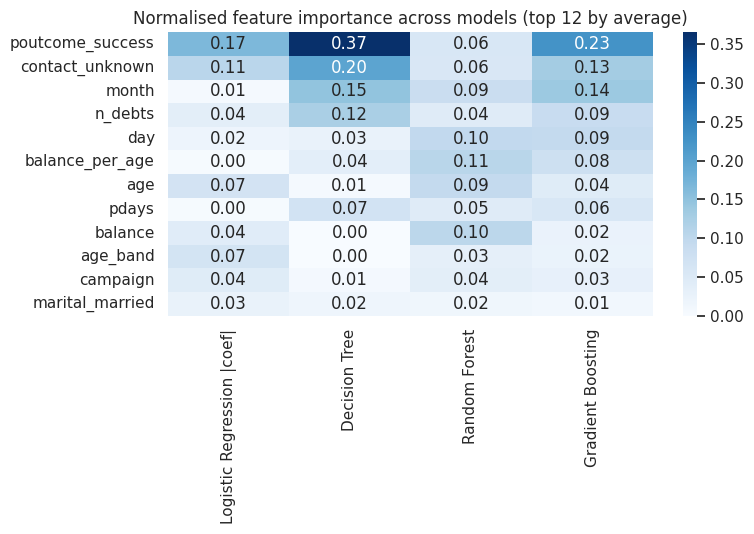

In [ ]:
imp = pd.DataFrame(index=X.columns)
imp['Logistic Regression |coef|'] = np.abs(models['Logistic Regression'].named_steps['clf'].coef_[0])
imp['Decision Tree'] = models['Decision Tree'].named_steps['clf'].feature_importances_
imp['Random Forest'] = models['Random Forest'].named_steps['clf'].feature_importances_
imp['Gradient Boosting'] = models['Gradient Boosting'].named_steps['clf'].feature_importances_
imp = imp / imp.sum()                      # each model's importances sum to 1 so they are comparable
imp['mean'] = imp.mean(axis=1)
top = imp.sort_values('mean', ascending=False).head(12).drop(columns='mean')
print(top.round(3))
plt.figure(figsize=(8, 5.5))
sns.heatmap(top, annot=True, fmt='.2f', cmap='Blues')
plt.title('Normalised feature importance across models (top 12 by average)')
plt.tight_layout()
print()
plt.show()

**Conclusions from importance.** Importances are normalised within each model, so we compare rank agreement, not absolute size. The robust drivers are those near the top in most models: `poutcome_success` is first for logistic regression, the decision tree and gradient boosting (and still important in the forest), `contact_unknown` (customers whose contact channel is unrecorded) is second for several models, and `month` is important for the tree models, which fits the seasonality found in SQL. Two of our engineered features earned their place: `n_debts` ranks high in the decision tree and gradient boosting, and `balance_per_age` ranks high in the random forest and gradient boosting. `age_band` and `total_contacts` add little beyond the raw columns. The random forest spreads importance over continuous columns (`day`, `balance`, `age`, `balance_per_age`), which is partly the known bias of impurity importance toward high-cardinality numeric features, so we treat that as less reliable than the agreement across the other three models. These are associations, not proof of causation: for example the contact-channel effect may reflect how the campaign was run rather than customer behaviour.

# Part 7. Conclusion and Recommendations

In [ ]:
# Final model: the best cross-validated learner (Gradient Boosting) with a cost-tuned threshold chosen on training out-of-fold predictions only
final_name = 'Gradient Boosting'
oof_final = cross_val_predict(clone(models[final_name]), X_train, y_train, cv=skf, method='predict_proba')[:, 1]
final_thr, _, _ = best_threshold(y_train, oof_final)
final_proba = proba_test[final_name]
final = evaluate(y_test, final_proba, final_thr)
dummy = rows['Stratified Dummy']
print('Cost per 1000 customers: thr 0.50 ->', round(cost_per_1000(y_test, final_proba, 0.5), 1),
      '| tuned thr', round(final_thr, 2), '->', round(cost_per_1000(y_test, final_proba, final_thr), 1))
print('Final precision / recall:', round(final['Precision'], 3), '/', round(final['Recall'], 3))
print('FINAL MODEL:', final_name, '(200 trees, depth 3), threshold', round(final_thr, 2))
print('Final  F1 / ROC AUC:', round(final['F1'], 2), '/', round(final['ROC AUC'], 2))
print('Dummy  F1 / ROC AUC:', round(dummy['F1'], 2), '/', round(dummy['ROC AUC'], 2))
print('Beats dummy on F1 :', final['F1'] > dummy['F1'], '| beats dummy on AUC:', final['ROC AUC'] > dummy['ROC AUC'])
print('AUC >= 0.75       :', final['ROC AUC'] >= 0.75)
print('Near-perfect score:', max(r['ROC AUC'] for r in rows.values()) > 0.97, '(must be False)')
print('Run time so far (min):', round((time.time() - T0) / 60, 1))

Cost per 1000 customers: thr 0.50 -> 618.5 | tuned thr 0.24 -> 475.6
Final precision / recall: 0.546 / 0.921
FINAL MODEL: Gradient Boosting (200 trees, depth 3), threshold 0.24
Final  F1 / ROC AUC: 0.69 / 0.79
Dummy  F1 / ROC AUC: 0.49 / 0.51
Beats dummy on F1 : True | beats dummy on AUC: True
AUC >= 0.75       : True
Near-perfect score: False (must be False)
Run time so far (min): 2.6


**Which model would we deploy and why.** We would deploy **gradient boosting with a cost-tuned threshold of about 0.24**. It has the best cross-validated AUC (about 0.788 +/- 0.004) and F1 and the best test AUC (about 0.79). Its threshold is chosen on out-of-fold training predictions (never the test set) to minimise 1 x false positives + 3 x false negatives. On the held-out test set that threshold gives recall about 0.92 and precision about 0.55, and cuts expected cost from about 621 to about 476 per 1,000 customers (about 23% lower) compared with the default 0.5 threshold. Test F1 (about 0.69) and ROC AUC (about 0.79) both clearly beat the stratified dummy (about 0.49 and 0.51), and the AUC clears the 0.75 bar. The random forest is a close alternative (AUC about 0.78) and is easier to tune, but boosting is consistently a little better and nothing about this data penalises its lower interpretability.

**What we would do with another month.** (1) Replace our assumed costs (1 per call, 3 per missed subscriber) with the bank's real call cost and margin per deposit, then re-tune the threshold; this is the single biggest lever (Part 5). (2) Tune hyper-parameters properly (learning rate, depth, number of trees) and calibrate the probabilities so they can be read as true likelihoods. (3) Validate with a time-based split, because the data come from campaigns spread over months and the model should hold on future campaigns. (4) Look for information available before the call (tenure, income, product holdings) that this file lacks, since our ceiling of about 0.79 AUC suggests that important drivers are not recorded here.

**What the clusters revealed that the classifier missed.** The classifier gives each customer a score but no story. The clusters give four describable segments: previously-contacted customers who subscribe about 66% of the time, a small group of older, debt-free, higher-balance customers at about 67%, a large group of new-to-campaign customers carrying debts (45% of customers) who subscribe only about 36% of the time, and an average group in between. That lets marketing write different scripts per segment (for example a warm follow-up for the previously-contacted group, and a cheaper low-touch approach for the indebted new customers) instead of treating the file as one list. The clusters also showed that segment membership explains only part of the outcome (cluster-only AUC about 0.64 against 0.79 for the model), so the classifier is needed to rank customers inside each segment.

**Hardest decision.** Dropping `duration`. It is the single most predictive column and removing it lowers the headline AUC, but it is only known after the call has happened, so a model using it cannot decide whom to call. We chose an honest, deployable AUC of about 0.79 over an impressive but meaningless one.